# So sánh các kernel và ảnh hưởng của C, gamma

*Bài 7, mục 7.1.3.* Dữ liệu hai nửa vầng trăng (`make_moons`). Đặc trưng được chuẩn hóa vì SVM dựa trên khoảng cách và tích vô hướng.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = make_moons(n_samples=300, noise=0.3, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 300), np.linspace(-1.3, 1.8, 300))


def plot_boundary(ax, model, title):
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz > 0, alpha=0.15, cmap='coolwarm')
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=0.8)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', s=12)
    ax.set_title(title, fontsize=10)

## 1. Ba kernel: tuyến tính, đa thức, RBF

kernel = linear: huấn luyện 0.814, kiểm tra 0.844
kernel = poly  : huấn luyện 0.924, kiểm tra 0.922


kernel = rbf   : huấn luyện 0.938, kiểm tra 0.944


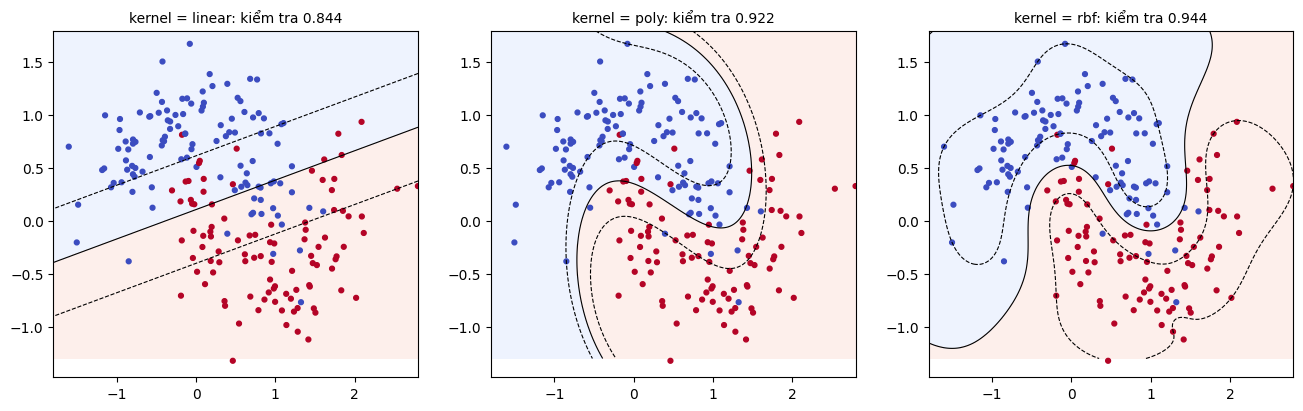

In [2]:
kernels = [('linear', {}), ('poly', {'degree': 3, 'coef0': 1}), ('rbf', {'gamma': 1})]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (kernel, params) in zip(axes, kernels):
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1, **params)).fit(X_train, y_train)
    train_acc, test_acc = model.score(X_train, y_train), model.score(X_test, y_test)
    print('kernel = %-6s: huấn luyện %.3f, kiểm tra %.3f' % (kernel, train_acc, test_acc))
    plot_boundary(ax, model, 'kernel = %s: kiểm tra %.3f' % (kernel, test_acc))
plt.show()

## 2. Ảnh hưởng của gamma (kernel RBF)

$\gamma$ nhỏ: mỗi vector hỗ trợ ảnh hưởng tới vùng rộng, ranh giới trơn (có thể chưa khớp). $\gamma$ lớn: ảnh hưởng chỉ trong vùng rất hẹp quanh mỗi điểm, ranh giới uốn lượn bao quanh từng điểm (quá khớp).

gamma = 0.1 : huấn luyện 0.838, kiểm tra 0.844, 91 vector hỗ trợ


gamma = 1   : huấn luyện 0.938, kiểm tra 0.944, 71 vector hỗ trợ


gamma = 50  : huấn luyện 0.981, kiểm tra 0.878, 194 vector hỗ trợ


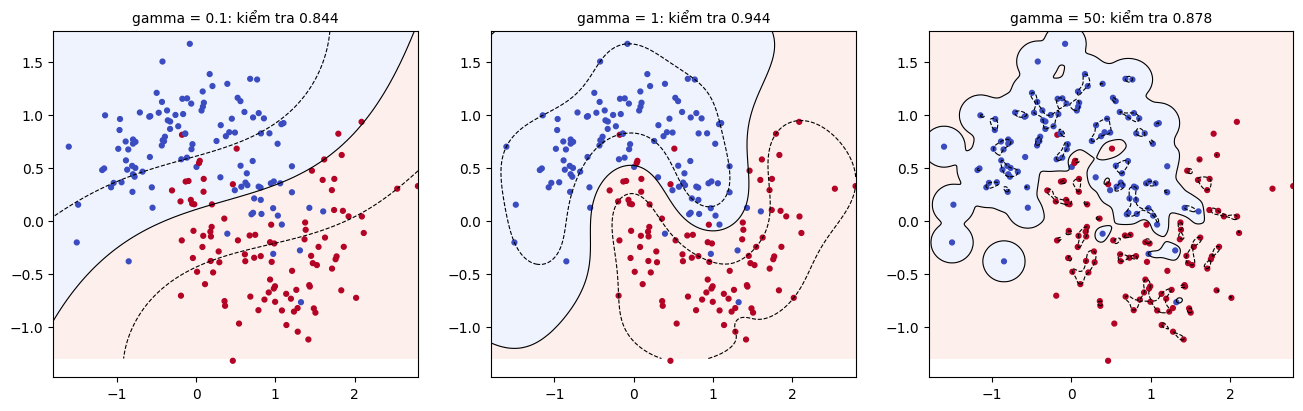

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, gamma in zip(axes, [0.1, 1, 50]):
    model = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma=gamma)).fit(X_train, y_train)
    print('gamma = %-4s: huấn luyện %.3f, kiểm tra %.3f, %d vector hỗ trợ'
          % (gamma, model.score(X_train, y_train), model.score(X_test, y_test), len(model[-1].support_)))
    plot_boundary(ax, model, 'gamma = %s: kiểm tra %.3f' % (gamma, model.score(X_test, y_test)))
plt.show()

## 3. Ảnh hưởng của C (kernel RBF)

In [4]:
for C in [0.01, 0.1, 1, 10, 100, 1000]:
    model = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=C, gamma=1)).fit(X_train, y_train)
    print('C = %-5s: huấn luyện %.3f, kiểm tra %.3f, %d vector hỗ trợ'
          % (C, model.score(X_train, y_train), model.score(X_test, y_test), len(model[-1].support_)))

C = 0.01 : huấn luyện 0.538, kiểm tra 0.411, 195 vector hỗ trợ
C = 0.1  : huấn luyện 0.910, kiểm tra 0.889, 138 vector hỗ trợ
C = 1    : huấn luyện 0.938, kiểm tra 0.944, 71 vector hỗ trợ
C = 10   : huấn luyện 0.948, kiểm tra 0.933, 52 vector hỗ trợ
C = 100  : huấn luyện 0.938, kiểm tra 0.944, 44 vector hỗ trợ
C = 1000 : huấn luyện 0.943, kiểm tra 0.956, 43 vector hỗ trợ


## 4. Chọn đồng thời C và gamma bằng kiểm định chéo

In [5]:
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
param_grid = {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.01, 0.1, 1, 10]}
search = GridSearchCV(pipe, param_grid, cv=5).fit(X_train, y_train)
print('Tốt nhất:', search.best_params_, ' kiểm định chéo %.3f' % search.best_score_)
print('Độ chính xác kiểm tra: %.3f' % search.score(X_test, y_test))

Tốt nhất: {'svc__C': 1, 'svc__gamma': 1}  kiểm định chéo 0.938
Độ chính xác kiểm tra: 0.944
